In [7]:
import numpy as np
import pandas as pd
import math
from uncertainties import unumpy as unp
from uncertainties import ufloat as uf
import numpy as np
import uncertainties.umath as umath
import matplotlib.pyplot as plt
from scipy import stats

def plot_power_law(x, y, xlabel=None, ylabel=None, title=None):
    """Log-log scatter plot of x vs y with a power-law fit y = a * x**b.

    x, y : pandas Series, arrays, or unumpy arrays of ufloats
           (only nominal values are used for the fit; values must be > 0)

    Returns
    -------
    a, b : ufloat   (prefactor and exponent)
    """
    # Works for plain floats and for ufloat arrays
    x = np.asarray(unp.nominal_values(np.asarray(x).ravel()), dtype=float)
    y = np.asarray(unp.nominal_values(np.asarray(y).ravel()), dtype=float)

    # Linear fit in log space: ln y = b ln x + ln a
    res = stats.linregress(np.log(x), np.log(y))
    b = uf(res.slope, res.stderr)
    ln_a = uf(res.intercept, res.intercept_stderr)
    a = umath.exp(ln_a)

    x_fit = np.linspace(0.9 * x.min(), 1.1 * x.max(), 200)
    y_fit = a.n * x_fit**b.n

    fig, ax = plt.subplots()
    ax.scatter(x, y, label="Data")
    ax.plot(
        x_fit, y_fit, color="red",
        label=f"Fit: y = ({a:.2uP}) x$^{{{b:.2uP}}}$\n"
              f"$R^2$ = {res.rvalue**2:.4f}",
    )

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.9 * x.min(), 1.1 * x.max())
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    if title:  ax.set_title(title)
    ax.legend()
    plt.show()

    return a, b

In [34]:
class info:
    D_box = 28.05 #cm
    R0 = 7.54 #kOhm

In [17]:
df_1 = pd.read_csv("g1_data.csv")
#print(df_1)

print(df_1.keys())

Index(['Voltage', 'Current', 'Power', 'Resistance', 'Temp'], dtype='str')


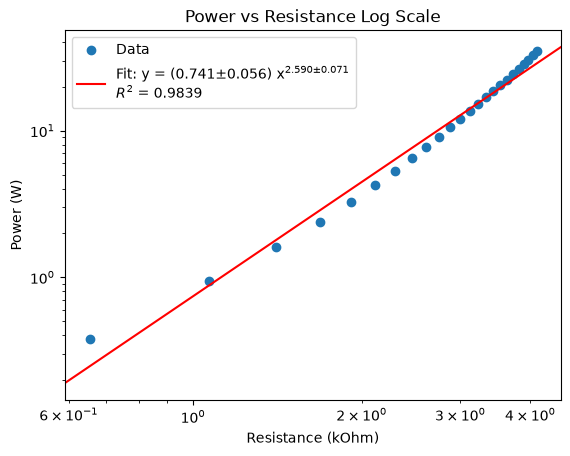

2.59+/-0.07


In [21]:
X = df_1["Resistance"].to_numpy()
Y = df_1["Power"].to_numpy()

a, power =  plot_power_law(X, Y, xlabel="Resistance (kOhm)", ylabel="Power (W)", title="Power vs Resistance Log Scale")

print(power)

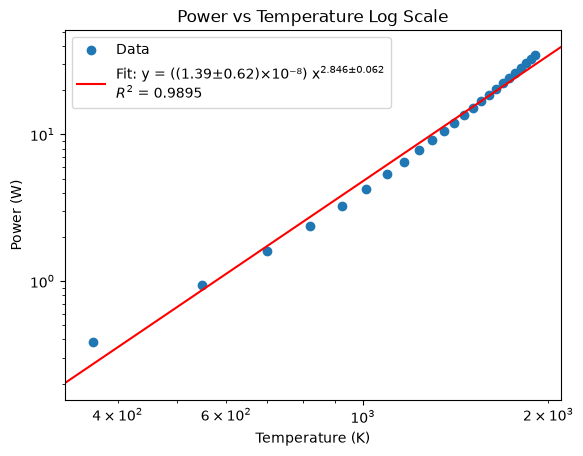

2.85+/-0.06


In [22]:
X = df_1["Temp"].to_numpy()
Y = df_1["Power"].to_numpy()

a, power =  plot_power_law(X, Y, xlabel="Temperature (K)", ylabel="Power (W)", title="Power vs Temperature Log Scale")

print(power)

In [23]:
df_2 = pd.read_csv("pos2_resistance.csv")

print(df_2)

    R_kOhm  Box_pos_cm       Unnamed: 2
0    18.13       30.05              NaN
1    17.21       30.15              NaN
2    16.63       30.25              NaN
3    15.89       30.75              NaN
4    14.99       31.00              NaN
5    14.30       31.30              NaN
6    13.74       31.60              NaN
7    13.12       31.90              NaN
8    12.62       32.05              NaN
9    12.23       32.20              NaN
10   11.76       32.50              NaN
11   11.36       32.80  Resistance_kOhm
12   11.04       33.00              NaN
13   10.49       33.50              NaN
14   10.25       34.00              NaN
15   10.03       34.50              NaN
16    9.73       35.00              NaN
17    9.23       36.00              NaN
18    9.17       37.00              NaN
19    8.67       38.00              NaN
20    7.50       39.00              NaN


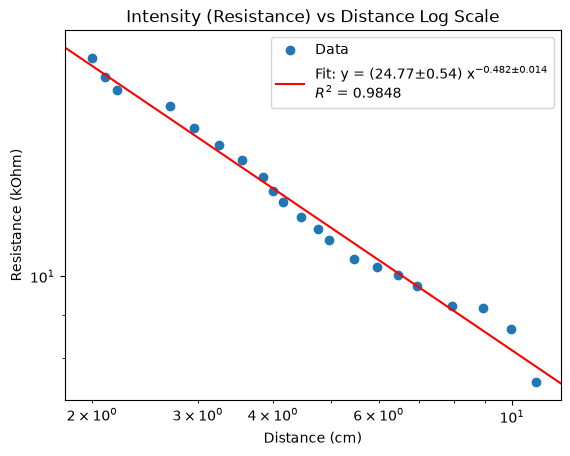

2.08+/-0.06


In [39]:
X = df_2["Box_pos_cm"].to_numpy()
X = X - info.D_box
#print(X)
Y = df_2["R_kOhm"].to_numpy()

a, power =  plot_power_law(X, Y, xlabel="Distance (cm)", ylabel="Resistance (kOhm)", title="Intensity (Resistance) vs Distance Log Scale")

print(-1/power)